# SBI812 Classroom Activity
## Building a Decision Tree by Hand and Checking It with Scikit-learn

### Aim of the activity

In this activity, the class will construct one decision tree from beginning to end. Every selected threshold must come from the data, and every decision must be supported by a Gini-impurity calculation.

The activity follows this sequence:

1. examine the original data;
2. calculate the impurity before splitting;
3. sort the first feature horizontally;
4. identify possible dividing positions and their midpoints;
5. compare candidate splits and select the root;
6. keep the pure branch and continue only with the mixed branch;
7. sort the remaining data again;
8. select the second decision;
9. draw the completed tree;
10. use the tree to predict new isolates by hand; and
11. compare the hand predictions with scikit-learn.

Work through each stage in order. Do not move to the next stage until the current decision can be justified.

## Activity data

Ten bacterial isolates have already been tested against an antibiotic.

| Isolate | Efflux expression | Growth rate | Known response |
|---|---:|---:|---|
| A | 2.1 | 0.50 | Sensitive |
| B | 2.8 | 0.58 | Sensitive |
| C | 3.7 | 0.62 | Sensitive |
| D | 4.9 | 0.66 | Sensitive |
| E | 5.4 | 0.48 | Resistant |
| F | 5.9 | 0.52 | Resistant |
| G | 6.4 | 0.55 | Resistant |
| H | 6.9 | 0.59 | Resistant |
| I | 7.2 | 0.75 | Sensitive |
| J | 8.4 | 0.78 | Sensitive |

The features are `efflux_expression` and `growth_rate`. The target to be predicted is `response`.

### First class task

Count the sensitive and resistant isolates.

- Number of sensitive isolates = ______
- Number of resistant isolates = ______
- Total number of isolates = ______

### Checkpoint 1

There are:

- 6 sensitive isolates: A, B, C, D, I and J;
- 4 resistant isolates: E, F, G and H;
- 10 isolates in total.

At this point, no split has been made. All ten observations are in the root node.

## Step 1 — Calculate the impurity of the root

The Gini formula for two classes is:

$$
Gini=1-p_{Sensitive}^2-p_{Resistant}^2
$$

Complete the calculation:

$$
p_{Sensitive}=\frac{\_\_\_}{10}=\_\_\_
$$

$$
p_{Resistant}=\frac{\_\_\_}{10}=\_\_\_
$$

$$
Gini_{root}=1-(\_\_\_)^2-(\_\_\_)^2=\_\_\_
$$

### Checkpoint 2

$$
p_{Sensitive}=\frac{6}{10}=0.6
$$

$$
p_{Resistant}=\frac{4}{10}=0.4
$$

$$
Gini_{root}=1-(0.6)^2-(0.4)^2
$$

$$
=1-0.36-0.16=0.48
$$

The root is mixed because its Gini impurity is greater than zero. The next task is to find a question that reduces this impurity.

## Step 2 — Sort efflux expression horizontally

The isolates are already arranged from the smallest efflux-expression value to the largest. Write the response below each value.

| Efflux expression | 2.1 | 2.8 | 3.7 | 4.9 | 5.4 | 5.9 | 6.4 | 6.9 | 7.2 | 8.4 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Response | S | S | S | S | R | R | R | R | S | S |

Here, `S` means Sensitive and `R` means Resistant.

Discuss the pattern before calculating anything:

1. Where does the first clear change from Sensitive to Resistant occur?
2. Which two neighbouring values surround that change?
3. Would placing a boundary there produce a pure group?

### Checkpoint 3

The first clear change occurs here:

```text
2.1   2.8   3.7   4.9  |  5.4   5.9   6.4   6.9   7.2   8.4
 S     S     S     S   |   R     R     R     R     S     S
                         ↑
              possible dividing position
```

The neighbouring values are `4.9` and `5.4`. A boundary between them would place A–D in a pure Sensitive group. This observation makes the boundary promising, but it must still be evaluated mathematically.

## Step 3 — Generate candidate thresholds

A threshold is placed halfway between two neighbouring values:

$$
\text{threshold}=\frac{\text{left value}+\text{right value}}{2}
$$

Calculate the missing midpoints.

| Neighbouring values | Calculation | Candidate threshold |
|---|---|---:|
| 2.1 and 2.8 | (2.1 + 2.8) / 2 | 2.45 |
| 2.8 and 3.7 | (2.8 + 3.7) / 2 | ______ |
| 3.7 and 4.9 | (3.7 + 4.9) / 2 | ______ |
| **4.9 and 5.4** | **(4.9 + 5.4) / 2** | **______** |
| 5.4 and 5.9 | (5.4 + 5.9) / 2 | ______ |
| 5.9 and 6.4 | (5.9 + 6.4) / 2 | ______ |
| 6.4 and 6.9 | (6.4 + 6.9) / 2 | ______ |
| 6.9 and 7.2 | (6.9 + 7.2) / 2 | ______ |
| 7.2 and 8.4 | (7.2 + 8.4) / 2 | ______ |

### Checkpoint 4

| Neighbouring values | Candidate threshold |
|---|---:|
| 2.1 and 2.8 | 2.45 |
| 2.8 and 3.7 | 3.25 |
| 3.7 and 4.9 | 4.30 |
| **4.9 and 5.4** | **5.15** |
| 5.4 and 5.9 | 5.65 |
| 5.9 and 6.4 | 6.15 |
| 6.4 and 6.9 | 6.65 |
| 6.9 and 7.2 | 7.05 |
| 7.2 and 8.4 | 7.80 |

`5.15` is not a measured value. It is the midpoint between the neighbouring measurements `4.9` and `5.4`.

## Step 4 — Evaluate the proposed root threshold 5.15

The proposed question is:

```text
Is efflux expression ≤ 5.15?
```

Place the samples into the two branches.

| Left branch: `efflux ≤ 5.15` | Right branch: `efflux > 5.15` |
|---|---|
| A: Sensitive | E: Resistant |
| B: Sensitive | F: Resistant |
| C: Sensitive | G: Resistant |
| D: Sensitive | H: Resistant |
|  | I: Sensitive |
|  | J: Sensitive |

Complete the counts:

| Branch | Sensitive | Resistant | Total |
|---|---:|---:|---:|
| Left | ______ | ______ | 4 |
| Right | ______ | ______ | 6 |

### Checkpoint 5 — Calculate both child impurities

The left branch contains 4 Sensitive and 0 Resistant isolates:

$$
Gini_{left}=1-\left(\frac{4}{4}\right)^2-\left(\frac{0}{4}\right)^2=0
$$

The right branch contains 2 Sensitive and 4 Resistant isolates:

$$
Gini_{right}=1-\left(\frac{2}{6}\right)^2-\left(\frac{4}{6}\right)^2
$$

$$
=1-0.1111-0.4444=0.4444
$$

The left branch is pure, but the right branch is still mixed.

## Step 5 — Calculate the weighted impurity

The child nodes contain different numbers of samples, so their Gini values must be weighted by their sizes:

$$
Gini_{split}=\frac{n_{left}}{n_{total}}Gini_{left}
+\frac{n_{right}}{n_{total}}Gini_{right}
$$

Substitute the values:

$$
Gini_{split}=\frac{4}{10}(0)+\frac{6}{10}(0.4444)
$$

Calculate:

$$
Gini_{split}=\_\_\_\_\_
$$

Then calculate the decrease from the parent impurity of 0.48:

$$
\text{impurity decrease}=0.48-Gini_{split}=\_\_\_\_\_
$$

### Checkpoint 6

$$
Gini_{split}=\frac{4}{10}(0)+\frac{6}{10}(0.4444)=0.2667
$$

$$
\text{impurity decrease}=0.48-0.2667=0.2133
$$

The split substantially reduces impurity and produces one completely pure child.

The software would perform the same calculation for every candidate threshold of both features. In this dataset, `efflux_expression ≤ 5.15` gives the best root split, so it becomes the first question.

## Step 6 — Draw the tree after the first decision

```text
                    Is efflux expression ≤ 5.15?
                              /       \
                            Yes        No
                            /           \
                4 Sensitive, 0 R     2 Sensitive, 4 R
                   Gini = 0            Gini = 0.4444
                       │                    │
             Predict Sensitive       Continue splitting
```

The left branch stops because it is pure. Only the six samples in the mixed right branch are used to find the next decision.

This is important: after a split, the algorithm does not return to all ten samples when building a child node.

## Step 7 — Work only with samples reaching the mixed branch

The remaining six isolates are:

| Isolate | Efflux expression | Growth rate | Response |
|---|---:|---:|---|
| E | 5.4 | 0.48 | Resistant |
| F | 5.9 | 0.52 | Resistant |
| G | 6.4 | 0.55 | Resistant |
| H | 6.9 | 0.59 | Resistant |
| I | 7.2 | 0.75 | Sensitive |
| J | 8.4 | 0.78 | Sensitive |

Now sort their growth rates horizontally:

| Growth rate | 0.48 | 0.52 | 0.55 | 0.59 | 0.75 | 0.78 |
|---|---:|---:|---:|---:|---:|---:|
| Response | R | R | R | R | S | S |

Identify the most promising dividing position before calculating the midpoint.

### Checkpoint 7 — Select the second candidate

```text
0.48   0.52   0.55   0.59  |  0.75   0.78
  R      R      R      R   |    S      S
                             ↑
                  possible dividing position
```

The neighbouring values are `0.59` and `0.75`. Their midpoint is:

$$
\frac{0.59+0.75}{2}=\frac{1.34}{2}=0.67
$$

The proposed second question is:

```text
Is growth rate ≤ 0.67?
```

## Step 8 — Evaluate the second split

Using `growth_rate ≤ 0.67`:

| Left child | Right child |
|---|---|
| E: Resistant | I: Sensitive |
| F: Resistant | J: Sensitive |
| G: Resistant |  |
| H: Resistant |  |

Calculate the Gini impurity of both children.

### Left child

$$
Gini_{left}=1-\left(\frac{0}{4}\right)^2-\left(\frac{4}{4}\right)^2=\_\_\_
$$

### Right child

$$
Gini_{right}=1-\left(\frac{2}{2}\right)^2-\left(\frac{0}{2}\right)^2=\_\_\_
$$

### Weighted impurity

$$
Gini_{split}=\frac{4}{6}Gini_{left}+\frac{2}{6}Gini_{right}=\_\_\_
$$

### Checkpoint 8

Both child nodes have Gini impurity 0:

$$
Gini_{left}=0, \qquad Gini_{right}=0
$$

Therefore:

$$
Gini_{split}=\frac{4}{6}(0)+\frac{2}{6}(0)=0
$$

The mixed parent node had Gini impurity 0.4444. The impurity decrease is:

$$
0.4444-0=0.4444
$$

This split separates the remaining classes perfectly. No further decisions are required.

## Step 9 — The completed decision tree

```text
                         ROOT
             Is efflux expression ≤ 5.15?
                     /             \
                   Yes              No
                   /                 \
         Predict Sensitive     Is growth rate ≤ 0.67?
                                   /             \
                                 Yes              No
                                 /                 \
                       Predict Resistant     Predict Sensitive
```

The tree can be written as three rules:

1. If `efflux_expression ≤ 5.15`, predict **Sensitive**.
2. Otherwise, if `growth_rate ≤ 0.67`, predict **Resistant**.
3. Otherwise, predict **Sensitive**.

## Step 10 — Predict new isolates by hand

Do not use Python yet. Start at the root and follow the branches.

| New isolate | Efflux expression | Growth rate | Q1: `efflux ≤ 5.15` | Q2, only if Q1 is No: `growth ≤ 0.67` | Prediction |
|---|---:|---:|---|---|---|
| K | 3.8 | 0.80 |  | — (stop if Q1 is Yes) |  |
| L | 6.1 | 0.54 |  |  |  |
| M | 7.5 | 0.74 |  |  |  |
| N | 5.0 | 0.40 |  | — (stop if Q1 is Yes) |  |
| O | 8.0 | 0.60 |  |  |  |

For each isolate:

1. answer Question 1;
2. stop if a leaf is reached;
3. otherwise answer Question 2; and
4. record the prediction.

### Important distinction

- **No** means that a question was asked and its condition was false.
- **— (tree stopped)** means that the question was never asked because an earlier branch had already produced a prediction.

For example, K has a growth rate of 0.80. It is mathematically true that `0.80 ≤ 0.67` is No. However, the tree does not perform that comparison for K because Q1 already sends K directly to a Sensitive leaf.

### Checkpoint 9 — Hand predictions

| New isolate | Q1 | Q2 | Prediction | Reason |
|---|---|---|---|---|
| K | Yes | — (tree stopped at Q1) | Sensitive | The first Yes branch reaches a leaf |
| L | No | Yes | Resistant | It moves right, then left |
| M | No | No | Sensitive | It moves right twice |
| N | Yes | — (tree stopped at Q1) | Sensitive | The first Yes branch reaches a leaf |
| O | No | Yes | Resistant | It moves right, then left |

The dash does not mean that the growth-rate value is missing. It means that the tree stopped before Q2. Q2 is asked only when the answer to Q1 is No.

## Step 11 — Enter the same data in Python

The following cells reproduce the activity with scikit-learn. Run them only after completing the hand calculations and predictions.

In [1]:
import pandas as pd

data = pd.DataFrame({
    "isolate": ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J"],
    "efflux_expression": [2.1, 2.8, 3.7, 4.9, 5.4, 5.9, 6.4, 6.9, 7.2, 8.4],
    "growth_rate": [0.50, 0.58, 0.62, 0.66, 0.48, 0.52, 0.55, 0.59, 0.75, 0.78],
    "response": ["Sensitive", "Sensitive", "Sensitive", "Sensitive",
                 "Resistant", "Resistant", "Resistant", "Resistant",
                 "Sensitive", "Sensitive"]
})

data

,isolate,efflux_expression,growth_rate,response
0,A,2.1,0.50,Sensitive
1,B,2.8,0.58,Sensitive
2,C,3.7,0.62,Sensitive
3,D,4.9,0.66,Sensitive
4,E,5.4,0.48,Resistant
5,F,5.9,0.52,Resistant
6,G,6.4,0.55,Resistant
7,H,6.9,0.59,Resistant
8,I,7.2,0.75,Sensitive
9,J,8.4,0.78,Sensitive


Separate the two feature columns from the target column:

In [2]:
X = data[["efflux_expression", "growth_rate"]]
y = data["response"]

Create and fit the decision tree. `max_depth=2` is used because the hand-built tree has at most two decisions along any path.

In [3]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=2,
    random_state=42
)

tree_model.fit(X, y)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

Display the fitted tree and compare its thresholds with the hand calculations.

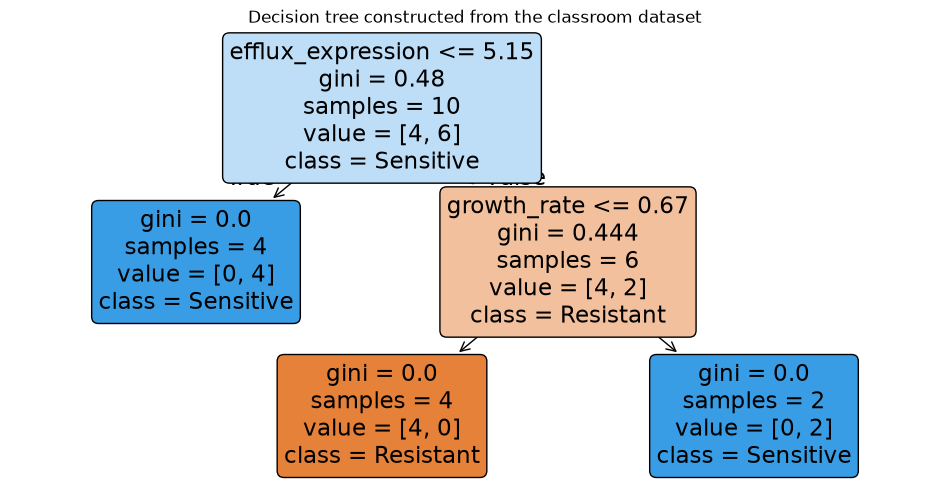

In [4]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(12, 6))

plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=tree_model.classes_,
    filled=True,
    rounded=True
)

plt.title("Decision tree constructed from the classroom dataset")
plt.show()

Finally, enter the five new isolates and compare the software predictions with the hand-prediction table.

In [5]:
new_isolates = pd.DataFrame({
    "efflux_expression": [3.8, 6.1, 7.5, 5.0, 8.0],
    "growth_rate": [0.80, 0.54, 0.74, 0.40, 0.60]
}, index=["K", "L", "M", "N", "O"])

new_isolates["predicted_response"] = tree_model.predict(new_isolates)
new_isolates

,efflux_expression,growth_rate,predicted_response
K,3.8,0.80,Sensitive
L,6.1,0.54,Resistant
M,7.5,0.74,Sensitive
N,5.0,0.40,Sensitive
O,8.0,0.60,Resistant


## Final discussion

1. Did the scikit-learn thresholds agree with the hand calculations?
2. Did all five software predictions agree with the hand predictions?
3. Why was growth rate not examined for isolates K and N?
4. Why were only six training isolates used when the second threshold was selected?
5. What would happen if a new isolate had `efflux_expression = 5.15` exactly?
6. Does a correct prediction on these examples prove that the model will always predict new biological samples correctly?

### Main conclusion

A decision tree does not invent its questions. It sorts the values available at the current node, proposes midpoints between neighbouring values, measures the impurity created by each possible split, and keeps the question that gives the strongest improvement.